In [3]:

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


from sklearn.decomposition import PCA


import joblib

In [4]:
df=pd.read_csv("../Datasets/datos_valle_limpios.csv")
print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (48223, 8)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48223 entries, 0 to 48222
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    48223 non-null  str    
 1   station_id  48223 non-null  int64  
 2   NO2         38825 non-null  float64
 3   O3          44853 non-null  float64
 4   CO          38468 non-null  float64
 5   PM2.5       40369 non-null  float64
 6   TMP         20304 non-null  float64
 7   HR          20441 non-null  float64
dtypes: float64(6), int64(1), str(1)
memory usage: 2.9 MB


#Preprocesamiento para el modelo
---
Lo primero es convertir la columna data '''datatime''' a un formato compatible con fechas para después ordenar y elegir los conjuntos de entrenamiento y prueba. 

In [6]:
df["datetime"] = pd.to_datetime(df["datetime"], format="%Y-%m-%d")
df["datetime"].info()

<class 'pandas.Series'>
RangeIndex: 48223 entries, 0 to 48222
Series name: datetime
Non-Null Count  Dtype         
--------------  -----         
48223 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 376.9 KB


In [7]:
df = df.sort_values(by="datetime", ascending=True)
df["datetime"].head(10)

33989   2000-01-01
29677   2000-01-01
41480   2000-01-01
12091   2000-01-01
20308   2000-01-01
41481   2000-01-02
20309   2000-01-02
12092   2000-01-02
29678   2000-01-02
33990   2000-01-02
Name: datetime, dtype: datetime64[us]

In [8]:
# Separar registros que tienen NO2 conocido
df_modelo = df.dropna(subset=["NO2"]).copy()

# Ordenar cronológicamente
df_modelo = df_modelo.sort_values("datetime")

# Obtener fechas únicas
fechas = np.sort(df_modelo["datetime"].unique())

# Seleccionar fecha de corte (80%)
indice_corte = int(len(fechas) * 0.8)
fecha_corte = fechas[indice_corte]

# Dividir entrenamiento y prueba
train_df = df_modelo[
    df_modelo["datetime"] < fecha_corte
].copy()

test_df = df_modelo[
    df_modelo["datetime"] >= fecha_corte
].copy()

print("Fecha de corte:", fecha_corte)
print("Entrenamiento:", train_df.shape)
print("Prueba:", test_df.shape)

print("Última fecha entrenamiento:",
      train_df["datetime"].max())

print("Primera fecha prueba:",
      test_df["datetime"].min())

Fecha de corte: 2019-11-19T00:00:00.000000
Entrenamiento: (30453, 8)
Prueba: (8372, 8)
Última fecha entrenamiento: 2019-11-18 00:00:00
Primera fecha prueba: 2019-11-19 00:00:00


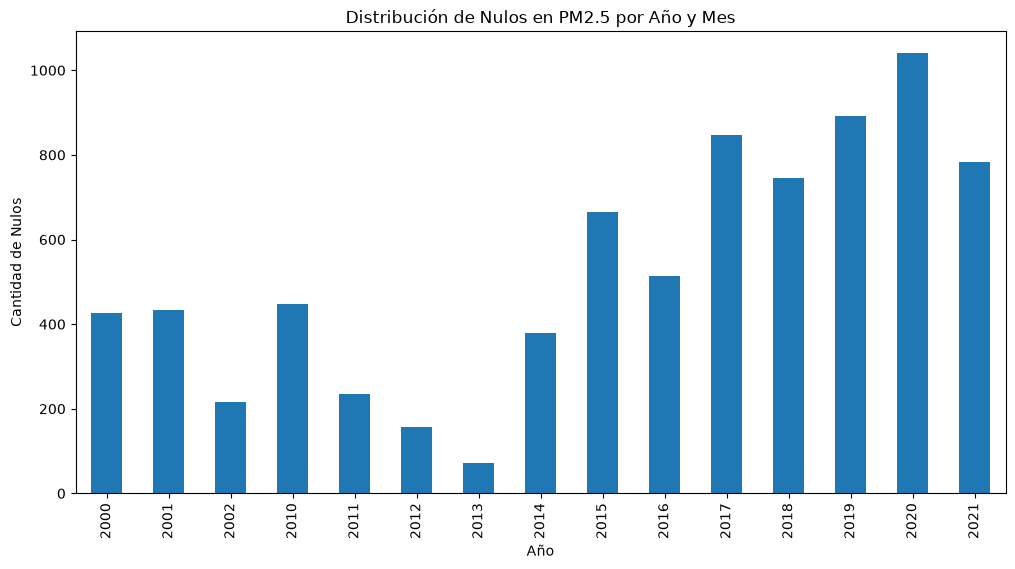

In [9]:
#revisar los nulos de la columna de PM2.5 con su año, para ver si hay algún patrón en los datos faltantes
df_nulos = df[df["PM2.5"].isnull()]
df_nulos["datetime"] = pd.to_datetime(df_nulos["datetime"], format="%Y-%m-%d")
df_nulos["year"] = df_nulos["datetime"].dt.year
#desplegar un gráfico de barras con los nulos de PM2.5 por año y mes
plt.figure(figsize=(12,6))
df_nulos.groupby("year").size().plot(kind="bar")
plt.xlabel("Año")
plt.ylabel("Cantidad de Nulos")
plt.title("Distribución de Nulos en PM2.5 por Año y Mes")
plt.show()

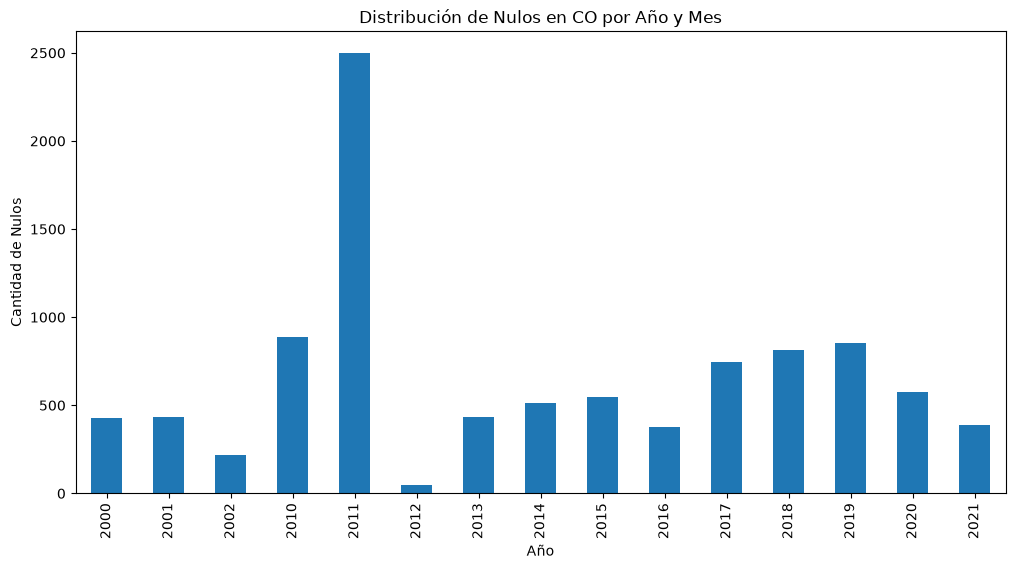

In [10]:
#revisar los nulos de la columna de CO con su año, para ver si hay algún patrón en los datos faltantes
df_nulos = df[df["CO"].isnull()]
df_nulos["datetime"] = pd.to_datetime(df_nulos["datetime"], format="%Y-%m-%d")
df_nulos["year"] = df_nulos["datetime"].dt.year
#desplegar un gráfico de barras con los nulos de CO por año y mes
plt.figure(figsize=(12,6))
df_nulos.groupby("year").size().plot(kind="bar")
plt.xlabel("Año")
plt.ylabel("Cantidad de Nulos")
plt.title("Distribución de Nulos en CO por Año y Mes")
plt.show()

---
Imputación de valores nulos
Notamos que las columnas elegidad para el modelo por su índice de correlación con '''NO2'''  contienen un gran porcentaje de nulos. Entonces, se imputaran '''O3, CO, PM2.5''' utlizando las medianas de cada estación de año para cada estación del Valle de México. 

In [11]:
def obtener_temporada(mes):
    if mes in [12, 1, 2]:
        return "Invierno"
    elif mes in [3, 4, 5]:
        return "Primavera"
    elif mes in [6, 7, 8]:
        return "Verano"
    else:
        return "Otoño"

In [12]:
variables = ["O3", "CO", "PM2.5"]

# Agregar temporada a cada conjunto
for datos in [train_df, test_df]:
    datos["temporada"] = (
        datos["datetime"].dt.month.apply(obtener_temporada)
    )

# Calcular medianas SOLO con entrenamiento
medianas = train_df.groupby(
    ["station_id", "temporada"]
)[variables].median()

# Medianas de respaldo por estación
medianas_estacion = train_df.groupby(
    "station_id"
)[variables].median()

# Medianas generales de entrenamiento
medianas_globales = train_df[variables].median()

display(medianas)

O3        CO      PM2.5
station_id temporada                               
242        Invierno   0.039944  0.600000  20.916667
           Otoño      0.031848  0.541667  15.272727
           Primavera  0.049042  0.515395  20.577381
           Verano     0.038682  0.550000  15.652174
244        Invierno   0.021396  1.010417  28.695652
           Otoño      0.020000  0.764583  21.863636
           Primavera  0.033913  0.800000  27.909091
           Verano     0.025500  0.640909  22.150000
245        Invierno   0.028417  0.714145  20.919437
           Otoño      0.026316  0.623810  14.190476
           Primavera  0.040425  0.573864  22.000000
           Verano     0.035227  0.509091  14.818182
251        Invierno   0.023792  1.033333  29.333333
           Otoño      0.022282  0.758333  20.727273
           Primavera  0.037444  0.795652  26.701993
           Verano     0.028583  0.675000  20.068182
256        Invierno   0.021361  1.200000  29.875000
           Otoño      0.020182  0.900000  21.590909
           Primavera  0.033375  0.958333  27.288538
           Verano     0.025378  0.857895  20.681159
258        Invierno   0.024085  0.950000  27.041667
           Otoño      0.023417  0.668182  15.976190
           Primavera  0.036667  0.764427  25.809524
           Verano     0.028619  0.610556  16.083333
260        Invierno   0.022381  0.958333  27.229167
           Otoño      0.021700  0.661538  18.479167
           Primavera  0.033667  0.710795  25.486842
           Verano     0.025417  0.560000  17.316667
262        Invierno   0.031375  0.600000  21.291667
           Otoño      0.023667  0.495238  15.363636
           Primavera  0.041850  0.518182  22.041667
           Verano     0.030456  0.535812  16.581169
263        Invierno   0.025458  0.870833  25.687500
           Otoño      0.024113  0.779167  18.604167
           Primavera  0.035875  0.704545  23.809524
           Verano     0.030739  0.662202  19.181818
266        Invierno   0.021250  1.000000  27.250000
           Otoño      0.020478  0.838095  21.170290
           Primavera  0.032483  0.862500  27.250000
           Verano     0.025150  0.787500  21.136364
268        Invierno   0.025417  0.910644  27.708333
           Otoño      0.023125  0.695833  21.000000
           Primavera  0.036250  0.739130  26.450000
           Verano     0.027545  0.627273  19.346591
269        Invierno   0.028583  0.826087  24.173913
           Otoño      0.024764  0.690476  15.869318
           Primavera  0.039583  0.737500  22.979167
           Verano     0.031833  0.619940  16.095238
271        Invierno   0.022604  1.252381  38.187500
           Otoño      0.022417  0.900000  22.863636
           Primavera  0.030750  0.963636  32.395833
           Verano     0.025351  0.826136  23.045455
302        Invierno   0.029408       NaN  27.458333
           Otoño      0.029765       NaN  17.568182
           Primavera  0.046864       NaN  31.613636
           Verano     0.036727       NaN  19.090909

In [13]:
print("Valores faltantes en entrenamiento:")
print(train_df[variables].isnull().sum())

print("\nValores faltantes en prueba:")
print(test_df[variables].isnull().sum())

print("\nMedianas generales:")
print(medianas_globales)

Valores faltantes en entrenamiento:
O3        687
CO       1959
PM2.5    3101
dtype: int64

Valores faltantes en prueba:
O3        131
CO        911
PM2.5    1862
dtype: int64

Medianas generales:
O3        0.027357
CO        0.750000
PM2.5    22.080128
dtype: float64


In [14]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

class ImputadorEstacional(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.variables = ["O3", "CO", "PM2.5"]

        self.medianas_ = X.groupby(
            ["station_id", "temporada"]
        )[self.variables].median()

        self.medianas_estacion_ = X.groupby(
            "station_id"
        )[self.variables].median()

        self.medianas_globales_ = X[self.variables].median()

        return self

    def transform(self, X):
        X = X.copy()

        for variable in self.variables:

            # Imputar por estación y temporada
            indice = pd.MultiIndex.from_frame(
                X[["station_id", "temporada"]]
            )

            valores = pd.Series(
                self.medianas_[variable].reindex(indice).to_numpy(),
                index=X.index
            )

            # Respaldo por estación
            valores = valores.fillna(
                X["station_id"].map(
                    self.medianas_estacion_[variable]
                )
            )

            # Respaldo general
            valores = valores.fillna(
                self.medianas_globales_[variable]
            )

            # Rellenar valores faltantes
            X[variable] = X[variable].fillna(valores)

        return X[self.variables]


pipeline_preprocesamiento = Pipeline([
    ("imputacion", ImputadorEstacional())
])

In [15]:
columnas = ["station_id", "temporada", "O3", "CO", "PM2.5"]

X_train = train_df[columnas]
X_test = test_df[columnas]

y_train = train_df["NO2"]
y_test = test_df["NO2"]

X_train_procesado = pipeline_preprocesamiento.fit_transform(X_train)
X_test_procesado = pipeline_preprocesamiento.transform(X_test)

print("Entrenamiento:", X_train_procesado.shape)
print("Prueba:", X_test_procesado.shape)

print("Nulos entrenamiento:",
      X_train_procesado.isnull().sum().sum())

print("Nulos prueba:",
      X_test_procesado.isnull().sum().sum())

Entrenamiento: (30453, 3)
Prueba: (8372, 3)
Nulos entrenamiento: 0
Nulos prueba: 0


In [16]:
columnas = ["station_id", "temporada", "O3", "CO", "PM2.5"]

X_train = train_df[columnas]
X_test = test_df[columnas]

y_train = train_df["NO2"]
y_test = test_df["NO2"]

X_train_procesado = pipeline_preprocesamiento.fit_transform(X_train)
X_test_procesado = pipeline_preprocesamiento.transform(X_test)

print("Entrenamiento:", X_train_procesado.shape)
print("Prueba:", X_test_procesado.shape)

print("Nulos entrenamiento:", X_train_procesado.isnull().sum().sum())
print("Nulos prueba:", X_test_procesado.isnull().sum().sum())

Entrenamiento: (30453, 3)
Prueba: (8372, 3)
Nulos entrenamiento: 0
Nulos prueba: 0


In [17]:

# Pipeline completo: imputación + regresión
modelo_lineal = Pipeline([
    ("imputacion", ImputadorEstacional()),
    ("modelo", LinearRegression())
])

# Entrenar únicamente con datos históricos
modelo_lineal.fit(X_train, y_train)

# Predecir NO2 en el conjunto de prueba
y_pred_lineal = modelo_lineal.predict(X_test)

# Evaluar resultados
mae = mean_absolute_error(y_test, y_pred_lineal)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lineal))
r2 = r2_score(y_test, y_pred_lineal)

print("REGRESIÓN LINEAL MÚLTIPLE")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

REGRESIÓN LINEAL MÚLTIPLE
MAE: 0.0053
RMSE: 0.0068
R²: 0.4062


In [18]:
# Pipeline completo
modelo_rf = Pipeline([
    ("imputacion", ImputadorEstacional()),
    ("modelo", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar
modelo_rf.fit(X_train, y_train)

# Predecir
y_pred_rf = modelo_rf.predict(X_test)

# Evaluar
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST REGRESSOR")
print(f"MAE: {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²: {r2_rf:.4f}")

RANDOM FOREST REGRESSOR
MAE: 0.0051
RMSE: 0.0066
R²: 0.4293
